# Waze: User Churn (Regression Modeling Stage)

Case study from the Google Advanced Data Analytics Professional Certificate (Course 4: Regression Analysis). Building a binomial logistic regression model to predict user churn for Waze and evaluating its performance.

# **Build a regression model**

## Plan

### Imports and data loading

In [1]:
# Packages for numerics + dataframes
import pandas as pd
import numpy as np

# Packages for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Packages for Logistic Regression & Confusion Matrix
from sklearn.model_selection  import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Load dataset into dataframe

df = pd.read_csv('waze_dataset.csv')

## Analyze

What are some purposes of EDA before constructing a binomial logistic regression model?

EDA helps you understand the data, clean it like missing values, outliers, and check that the data fits the model's assumptions before you fit it.

### Data exploration

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       14999 non-null  int64  
 1   label                    14299 non-null  object 
 2   sessions                 14999 non-null  int64  
 3   drives                   14999 non-null  int64  
 4   total_sessions           14999 non-null  float64
 5   n_days_after_onboarding  14999 non-null  int64  
 6   total_navigations_fav1   14999 non-null  int64  
 7   total_navigations_fav2   14999 non-null  int64  
 8   driven_km_drives         14999 non-null  float64
 9   duration_minutes_drives  14999 non-null  float64
 10  activity_days            14999 non-null  int64  
 11  driving_days             14999 non-null  int64  
 12  device                   14999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.5+ MB


In [4]:
df.shape

(14999, 13)

**Question:** Are there any missing values in your data?

label has 700 missing values

In [5]:
df.head()

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android


In [6]:
df = df.drop(columns=["ID"], axis=1)

In [7]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

retained    11763
churned      2536
Name: label, dtype: int64
retained    0.822645
churned     0.177355
Name: label, dtype: float64


In [8]:
df.describe()

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879
std,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036
min,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000
25%,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000
50%,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000
75%,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000
max,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000


**Question:** Are there any variables that could potentially have outliers just by assessing at the quartile values, standard deviation, and max values?

From the look of the describe(), there are probably seven outliers.

### Create features

#### **`km_per_driving_day`**

Churn rate correlates with distance driven per driving day in the last month, so it might be helpful to engineer a feature that captures this information: the mean distance driven per driving day for each user.

In [9]:
# 1. Create `km_per_driving_day` column
df["km_per_driving_day"] = df["driven_km_drives"] / df["driving_days"]

# 2. Call `describe()` on the new column
df["km_per_driving_day"].describe()

count    1.499900e+04
mean              inf
std               NaN
min      3.022063e+00
25%      1.672804e+02
50%      3.231459e+02
75%      7.579257e+02
max               inf
Name: km_per_driving_day, dtype: float64

Note that some values are infinite. This is the result of there being values of zero in the `driving_days` column. Pandas imputes a value of infinity in the corresponding rows of the new column because division by zero is undefined. These values are converted to zero.

In [10]:
# 1. Convert infinite values to zero
df["km_per_driving_day"] = df["km_per_driving_day"].replace([np.inf,-np.inf], 0)

# 2. Confirm that it worked
df["km_per_driving_day"].describe()

count    14999.000000
mean       578.963113
std       1030.094384
min          0.000000
25%        136.238895
50%        272.889272
75%        558.686918
max      15420.234110
Name: km_per_driving_day, dtype: float64

#### **`professional_driver`**

A binary feature that is a 1 for users who had 60 or more drives <u>**and**</u> drove on 15+ days in the last month. The objective is to separate professional drivers from other drivers. Domain knowledge and intuition are used to set these thresholds, but ultimately they are arbitrary.

In [11]:
# Create `professional_driver` column
df["professional_driver"] = np.where((df["drives"] >= 60)&(df["driving_days"] >= 15),1,0)

In [12]:
# 1. Check count of professionals and non-professionals
print(df["professional_driver"].value_counts())

# 2. Check in-class churn rate
print(df.groupby("professional_driver")["label"].value_counts(normalize=True))

0    12405
1     2594
Name: professional_driver, dtype: int64
professional_driver  label   
0                    retained    0.801202
                     churned     0.198798
1                    retained    0.924437
                     churned     0.075563
Name: label, dtype: float64


The churn rate for professional drivers is 7.6%, while the churn rate for non-professionals is 19.9%. This seems like it could add predictive signal to the model.

## Construct

Why did you select the X variables you did?

It felt right

### Preparing variables

In [13]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   label                    14299 non-null  object 
 1   sessions                 14999 non-null  int64  
 2   drives                   14999 non-null  int64  
 3   total_sessions           14999 non-null  float64
 4   n_days_after_onboarding  14999 non-null  int64  
 5   total_navigations_fav1   14999 non-null  int64  
 6   total_navigations_fav2   14999 non-null  int64  
 7   driven_km_drives         14999 non-null  float64
 8   duration_minutes_drives  14999 non-null  float64
 9   activity_days            14999 non-null  int64  
 10  driving_days             14999 non-null  int64  
 11  device                   14999 non-null  object 
 12  km_per_driving_day       14999 non-null  float64
 13  professional_driver      14999 non-null  int64  
dtypes: float64(4), int64(8

Because you know from previous EDA that there is no evidence of a non-random cause of the 700 missing values in the `label` column, and because these observations comprise less than 5% of the data, the rows that are missing this data are dropped.

In [14]:
# Drop rows with missing data in `label` column
df = df.dropna(subset=["label"])

#### **Impute outliers**

In [15]:
# Impute outliers
def outlierimpute(df, col):
    th95 = df[col].quantile(0.95)
    df[col] = df[col].clip(upper = th95)
  
for col in ["sessions", "drives", "total_sessions", "total_navigations_fav1",
            "total_navigations_fav2", "driven_km_drives", "duration_minutes_drives"]:
    outlierimpute(df, col)

In [16]:
df.describe()

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day,professional_driver
count,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000,14299.000000
mean,76.539688,63.964683,183.717304,1751.822505,114.562767,27.187216,3944.558631,1792.911210,15.544653,12.182530,581.942399,0.173998
std,67.243178,55.127927,118.720520,1008.663834,124.378550,36.715302,2218.358258,1224.329759,9.016088,7.833835,1038.254509,0.379121
min,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000,0.000000
25%,23.000000,20.000000,90.457733,878.500000,10.000000,0.000000,2217.319909,840.181344,8.000000,5.000000,136.168003,0.000000
50%,56.000000,48.000000,158.718571,1749.000000,71.000000,9.000000,3496.545617,1479.394387,16.000000,12.000000,273.301012,0.000000
75%,111.000000,93.000000,253.540450,2627.500000,178.000000,43.000000,5299.972162,2466.928876,23.000000,19.000000,558.018761,0.000000
max,243.000000,200.000000,455.439492,3500.000000,422.000000,124.000000,8898.716275,4668.180092,31.000000,30.000000,15420.234110,1.000000


#### **Encode categorical variables**

The `label` column is changed to binary, which is needed to train a logistic regression model: `0` for all `retained` users and `1` for all `churned` users. It is saved as `label2` so the original `label` variable isn't overwritten.

In [17]:
# Create binary `label2` column
df["label2"] = np.where(df["label"] == "retained", 0,1)

### Determine whether assumptions have been met

The following are the assumptions for logistic regression:

* Independent observations (This refers to how the data was collected.)

* No extreme outliers

* Little to no multicollinearity among X predictors

* Linear relationship between X and the **logit** of y

For the first assumption, observations are assumed to be independent for this project. The second assumption has already been addressed. The last assumption is verified after modeling.

#### **Collinearity**

In [18]:
# Generate a correlation matrix
df_heat = df.corr()

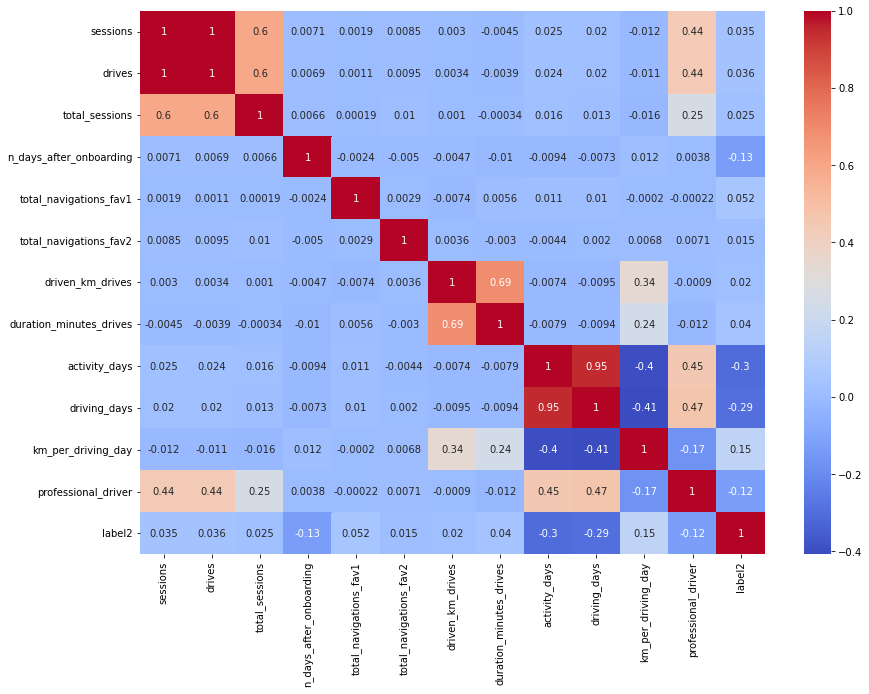

In [19]:
# Plot correlation heatmap
plt.figure(figsize=(14,10))
sns.heatmap(df_heat, annot=True, cmap='coolwarm')

If there are predictor variables that have a Pearson correlation coefficient value greater than the **absolute value of 0.7**, these variables are strongly multicollinear. Therefore, only one of these variables should be used in your model.

**Question:** Which variables are multicollinear with each other?

Sessions and drives (1.00) , activity_days and driving_days (0.95).

### Create dummies

`device` is the only remaining categorical feature, so it is encoded directly as a new binary column called `device2`:

* `Android` -> `0`
* `iPhone` -> `1`

In [20]:
# Create new `device2` variable
df["device2"] = np.where(df["device"] == "Android", 0, 1)


### Model building

#### **Assign predictor variables and target**

The target is `label2`. The following variables are dropped to create `X`:

* `label` (this is the target)
* `label2` (this is the target)
* `device` (this is the non-binary-encoded categorical variable)
* `sessions` (this had high multicollinearity)
* `driving_days` (this had high multicollinearity)

**Note:** `sessions` and `driving_days` were dropped, rather than `drives` and `activity_days`, because the features that were kept for modeling had slightly stronger correlations with the target variable than the features that were dropped.

In [21]:
# Isolate predictor variables
x = df.drop(columns=["label","label2", "device","sessions","driving_days"])

In [22]:
# Isolate target variable
y = df["label2"]

#### **Split the data**

The model is fit on the training set and evaluated on the test set to avoid data leakage. Because the target class is imbalanced (82% retained vs. 18% churned), `stratify=y` ensures that the minority class appears in both train and test sets in the same proportion that it does in the overall dataset.

In [23]:
# Perform the train-test split
x_train , x_test , y_train, y_test = train_test_split(x,y,stratify=y, test_size = 0.25 ,random_state=23)

In [24]:
# Use .head()
x_train.head()

,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,km_per_driving_day,professional_driver,device2
10193,102.0,112.870102,149,82.0,0.0,2174.920238,1786.508526,20,114.469486,1,1
10558,23.0,53.261607,2924,35.0,11.0,7373.238231,4668.180092,28,368.661912,0,0
3388,160.0,375.196115,2834,330.0,16.0,4579.316016,2069.318982,7,654.188002,0,1
6912,71.0,125.198503,2663,48.0,124.0,3956.750696,2356.261000,24,219.819483,1,0
13738,41.0,87.289313,1482,16.0,3.0,1535.849301,728.946109,31,61.433972,0,1


The model is instantiated with no penalty, since the predictors are unscaled.

In [25]:
lr = LogisticRegression(penalty="none", max_iter=500).fit(x_train,y_train)

The coefficients are in the order the variables are listed in the dataset. They represent the change in the **log odds** of the target variable for **every one unit increase in X**.

In [26]:
lr.coef_

array([[ 2.19345853e-03,  1.27380694e-04, -3.87261997e-04,
         1.30394952e-03,  8.30609959e-04, -2.04560221e-05,
         9.26787807e-05, -1.03729673e-01,  1.89943799e-05,
        -1.54245729e-03, -8.52551027e-04]])

In [27]:
lr.intercept_

array([-0.00153689])

#### **Check final assumption**

Verify the linear relationship between X and the estimated log odds (known as logits) with a regplot. `predict_proba()` returns a 2-D array where each row is a user in `X_train`: the first column is the probability of the user not churning, and the second column is the probability of the user churning.

In [40]:
# Get the predicted probabilities of the training data
training_probabilities = lr.predict_proba(x_train)
training_probabilities

array([[0.84130068, 0.15869932],
       [0.97435673, 0.02564327],
       [0.70539557, 0.29460443],
       ...,
       [0.65864756, 0.34135244],
       [0.94265531, 0.05734469],
       [0.94219929, 0.05780071]])

In logistic regression, the relationship between a predictor variable and the dependent variable does not need to be linear, however, the log-odds (a.k.a., logit) of the dependent variable with respect to the predictor variable should be linear. Here is the formula for calculating log-odds, where _p_ is the probability of response:
<br>
$$
logit(p) = ln(\frac{p}{1-p})
$$
<br>

In [41]:
# 1. Copy the `X_train` dataframe and assign to `logit_data`
logit_data = x_train.copy()

# 2. Create a new `logit` column in the `logit_data` df
from scipy.special import logit
logit_data["logit"] = logit(training_probabilities[:, 1])

In an exhaustive analysis, this would be plotted for each continuous or discrete predictor variable. Here only `activity_days` is shown.

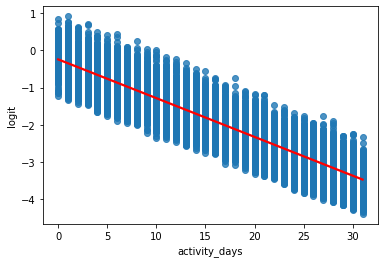

In [44]:
# Plot regplot of `activity_days` log-odds
sns.regplot(data=logit_data ,x= "activity_days" , y="logit", line_kws={"color": "red"} )

## Execute

### Results and evaluation

In [45]:
# Generate predictions on X_test
y_pred = lr.predict(x_test)

In [46]:
# Score the model (accuracy) on the test data
lr.score(x_test,y_test)

0.8257342657342658

### Show results with a confusion matrix

In [48]:
cm = confusion_matrix(y_test, y_pred)

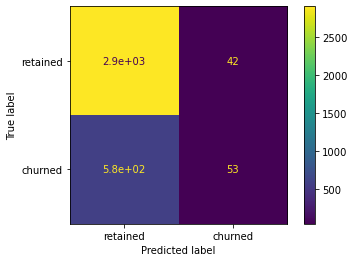

In [57]:
cmd = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=["retained","churned"])
cmd.plot()

In [61]:
# Calculate precision manually
cm[1, 1] / (cm[1, 1] + cm[0, 1])

0.5578947368421052

In [62]:
# Calculate recall manually
cm[1, 1] / (cm[1, 1] + cm[1, 0])

0.083596214511041

In [60]:
# Create a classification report
print(classification_report(y_test, y_pred, target_names=['retained', 'churned']))

              precision    recall  f1-score   support

    retained       0.83      0.99      0.90      2941
     churned       0.56      0.08      0.15       634

    accuracy                           0.83      3575
   macro avg       0.70      0.53      0.52      3575
weighted avg       0.78      0.83      0.77      3575



**Note:** The model has decent precision but very low recall, which means that it makes a lot of false negative predictions and fails to capture users who will churn.

### BONUS

A bar graph of the model's coefficients as a visual representation of the importance of the model's features.

In [63]:
# Create a list of (column_name, coefficient) tuples
feat = list(zip(x_train.columns, lr.coef_[0]))
# Sort the list by coefficient value
sorted(feat, key=lambda x: x[1])

[('activity_days', -0.10372967273708532),
 ('professional_driver', -0.0015424572855473975),
 ('device2', -0.0008525510274432144),
 ('n_days_after_onboarding', -0.0003872619971133945),
 ('driven_km_drives', -2.0456022103215866e-05),
 ('km_per_driving_day', 1.8994379940527595e-05),
 ('duration_minutes_drives', 9.267878066988893e-05),
 ('total_sessions', 0.00012738069391993493),
 ('total_navigations_fav2', 0.0008306099593812124),
 ('total_navigations_fav1', 0.0013039495165528593),
 ('drives', 0.002193458534392207)]

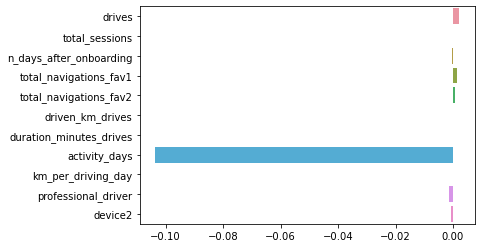

In [64]:
# Plot the feature importances
sns.barplot(x=[x[1] for x in feat], y=[x[0] for x in feat])

### Conclusion

**Questions:**

1. What variable most influenced the model's prediction? How? Was this surprising?

2. Were there any variables that you expected to be stronger predictors than they were?

3. Why might a variable you thought to be important not be important in the model?

4. Would you recommend that Waze use this model? Why or why not?

5. What could you do to improve this model?

6. What additional features would you like to have to help improve the model?


1- activity_days It has a negative coefficient so maybe more active days means less chance of churning. This isn't surprising.

2- km_per_driving_day I expected heavy drivers to behave differently, but it had little effect.

3- It overlaps with other variables or its relationship with churn isn't linear.

4- No not as it is. Accuracy is okay, but recall for churned users is low, so it misses most of the people who leave.

5- Try random forest or XGBoost, lower the threshold, and engineer better features.

6- App crashes, support complaints, and how users use specific features.